In [10]:
!pip install ucimlrepo

In [11]:
import os
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"

import json
import hashlib
import platform
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits, threadpool_info
from ucimlrepo import fetch_ucirepo
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, make_scorer,
)
from sklearn.exceptions import ConvergenceWarning

SEED = 42
CLASSES = ["<=50K", ">50K"]
CODIGO_CLASSES = {"<=50K": 0, ">50K": 1}
target_column = "income"
np.random.seed(SEED)
_limite_threads = threadpool_limits(limits=2)
sns.set_theme(style="whitegrid", palette="Blues_r")
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 20)

In [12]:
adult = fetch_ucirepo(id=2)
dataset_original = pd.concat([adult.data.features, adult.data.targets], axis=1).copy()
dataset_original.columns = dataset_original.columns.str.strip()
assert dataset_original.shape == (48842, 15), "A fonte mudou: revisar antes da comparação."
assert target_column in dataset_original.columns
hash_fonte = hashlib.sha256(dataset_original.to_csv(index=False).encode("utf-8")).hexdigest()
print("Formato original:", dataset_original.shape)
print("SHA-256 da representação CSV recebida:", hash_fonte)
display(dataset_original.head())

Formato original: (48842, 15)
SHA-256 da representação CSV recebida: 82682cd3606b1c0592975abff21db758baed235950a2a9c02931c56f1b8157ee


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Limpeza determinística e caracterização dos dados

Removemos espaços dos textos, transformamos `?` em ausente e retiramos o ponto
final dos rótulos de renda da partição original de teste. Esses passos não estimam
parâmetros. O alvo permanece ausente quando não informado: não é convertido em texto
`"nan"`. A caracterização considera todos os 14 atributos originais, inclusive
`fnlwgt`, antes de sua remoção. Os resumos do conjunto completo têm finalidade
descritiva; imputadores e escalas serão aprendidos apenas no treino.

In [13]:
dataset = dataset_original.copy()
for col in dataset.select_dtypes(include=["object", "string"]).columns:
    dataset[col] = dataset[col].str.strip()
dataset = dataset.replace("?", np.nan)
dataset[target_column] = dataset[target_column].str.replace(r"\.$", "", regex=True)
sem_alvo = int(dataset[target_column].isna().sum())
dataset = dataset.dropna(subset=[target_column]).copy()
assert set(dataset[target_column].unique()) == set(CLASSES)
print("Registros removidos por ausência de alvo:", sem_alvo)

linhas = []
dominancia = []
for col in dataset.columns:
    serie = dataset[col]
    numerica = pd.api.types.is_numeric_dtype(serie)
    valores = (f"[{serie.min():g}, {serie.max():g}]" if numerica else
               ", ".join(sorted(serie.dropna().unique().tolist())))
    linhas.append({
        "Atributo": col,
        "Papel": "Alvo" if col == target_column else "Preditor",
        "Tipo": "Numérico inteiro" if numerica else "Categórico nominal",
        "dtype": str(serie.dtype), "Valores distintos": serie.nunique(),
        "Intervalo ou conjunto de valores": valores,
        "Ausentes": int(serie.isna().sum()),
        "Ausentes (%)": serie.isna().mean() * 100,
    })
    contagens = serie.dropna().value_counts()
    dominancia.append({
        "Atributo": col, "Valor mais frequente": str(contagens.index[0]),
        "Frequência": int(contagens.iloc[0]),
        "Dominância (%)": contagens.iloc[0] / serie.notna().sum() * 100,
    })
caracterizacao = pd.DataFrame(linhas)
desbalanceamento = pd.DataFrame(dominancia).sort_values("Dominância (%)", ascending=False)
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(caracterizacao.style.format({"Ausentes (%)": "{:.2f}%"}).set_properties(
        subset=["Intervalo ou conjunto de valores"],
        **{"white-space": "normal", "min-width": "260px", "max-width": "480px", "overflow-wrap": "anywhere"}
    ).hide(axis="index"))
faltantes = caracterizacao.loc[caracterizacao["Ausentes"] > 0,
                             ["Atributo", "Ausentes", "Ausentes (%)"]]
display(faltantes.style.format({"Ausentes (%)": "{:.2f}%"}).hide(axis="index"))
print(f"Atributos com valores faltantes: {len(faltantes)}")
print(f"Linhas com pelo menos um valor faltante: {dataset.isna().any(axis=1).sum()}")
display(desbalanceamento.style.format({"Dominância (%)": "{:.2f}%"}).hide(axis="index"))
maior = desbalanceamento.iloc[0]
display(Markdown(
    f"Pelo critério **proporção do valor exato mais frequente entre os não ausentes**, "
    f"o atributo mais concentrado é **`{maior['Atributo']}`**: "
    f"o valor `{maior['Valor mais frequente']}` representa **{maior['Dominância (%)']:.2f}%**. "
    "Em atributos numéricos, esse critério detecta concentrações como muitos zeros; "
    "não mede assimetria contínua nem substitui a análise das classes do alvo."
))

Registros removidos por ausência de alvo: 0


Atributo,Papel,Tipo,dtype,Valores distintos,Intervalo ou conjunto de valores,Ausentes,Ausentes (%)
age,Preditor,Numérico inteiro,int64,74,"[17, 90]",0,0.00%
workclass,Preditor,Categórico nominal,object,8,"Federal-gov, Local-gov, Never-worked, Private, Self-emp-inc, Self-emp-not-inc, State-gov, Without-pay",2799,5.73%
fnlwgt,Preditor,Numérico inteiro,int64,28523,"[12285, 1.4904e+06]",0,0.00%
education,Preditor,Categórico nominal,object,16,"10th, 11th, 12th, 1st-4th, 5th-6th, 7th-8th, 9th, Assoc-acdm, Assoc-voc, Bachelors, Doctorate, HS-grad, Masters, Preschool, Prof-school, Some-college",0,0.00%
education-num,Preditor,Numérico inteiro,int64,16,"[1, 16]",0,0.00%
marital-status,Preditor,Categórico nominal,object,7,"Divorced, Married-AF-spouse, Married-civ-spouse, Married-spouse-absent, Never-married, Separated, Widowed",0,0.00%
occupation,Preditor,Categórico nominal,object,14,"Adm-clerical, Armed-Forces, Craft-repair, Exec-managerial, Farming-fishing, Handlers-cleaners, Machine-op-inspct, Other-service, Priv-house-serv, Prof-specialty, Protective-serv, Sales, Tech-support, Transport-moving",2809,5.75%
relationship,Preditor,Categórico nominal,object,6,"Husband, Not-in-family, Other-relative, Own-child, Unmarried, Wife",0,0.00%
race,Preditor,Categórico nominal,object,5,"Amer-Indian-Eskimo, Asian-Pac-Islander, Black, Other, White",0,0.00%
sex,Preditor,Categórico nominal,object,2,"Female, Male",0,0.00%


Atributo,Ausentes,Ausentes (%)
workclass,2799,5.73%
occupation,2809,5.75%
native-country,857,1.75%


Atributos com valores faltantes: 3
Linhas com pelo menos um valor faltante: 3620


Atributo,Valor mais frequente,Frequência,Dominância (%)
capital-loss,0,46560,95.33%
capital-gain,0,44807,91.74%
native-country,United-States,43832,91.35%
race,White,41762,85.50%
income,<=50K,37155,76.07%
workclass,Private,33906,73.64%
sex,Male,32650,66.85%
hours-per-week,40,22803,46.69%
marital-status,Married-civ-spouse,22379,45.82%
relationship,Husband,19716,40.37%


Pelo critério **proporção do valor exato mais frequente entre os não ausentes**, o atributo mais concentrado é **`capital-loss`**: o valor `0` representa **95.33%**. Em atributos numéricos, esse critério detecta concentrações como muitos zeros; não mede assimetria contínua nem substitui a análise das classes do alvo.

,Quantidade,Proporção (%)
income,,
<=50K,37155,76.07%
>50K,11687,23.93%


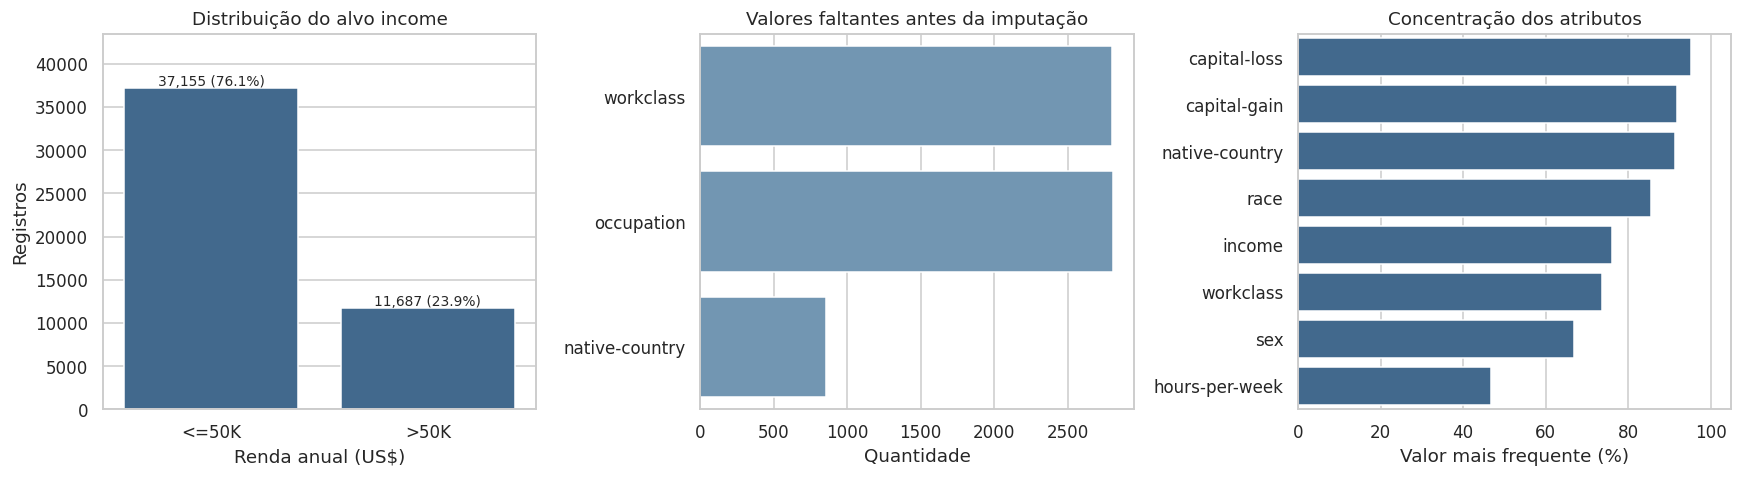

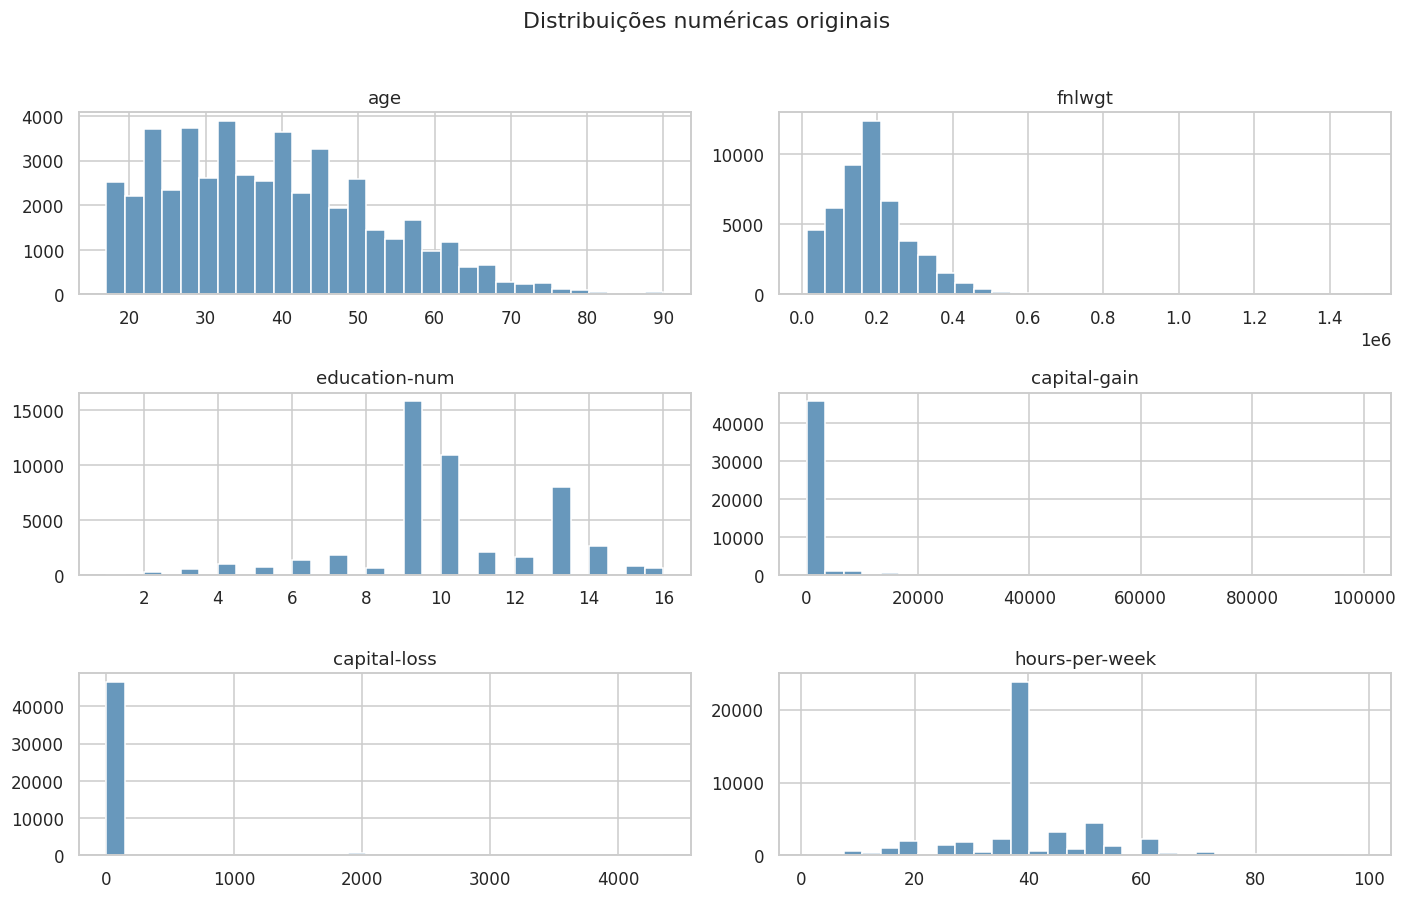

In [14]:
distribuicao_alvo = dataset[target_column].value_counts().reindex(CLASSES).to_frame("Quantidade")
distribuicao_alvo["Proporção (%)"] = distribuicao_alvo["Quantidade"] / len(dataset) * 100
display(distribuicao_alvo.style.format({"Proporção (%)": "{:.2f}%"}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.barplot(x=distribuicao_alvo.index, y=distribuicao_alvo["Quantidade"], ax=axes[0], color="#356a9a")
axes[0].set(title="Distribuição do alvo income", xlabel="Renda anual (US$)", ylabel="Registros")
for i, (_, row) in enumerate(distribuicao_alvo.iterrows()):
    axes[0].text(i, row["Quantidade"], f"{int(row['Quantidade']):,} ({row['Proporção (%)']:.1f}%)",
                 ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, distribuicao_alvo["Quantidade"].max() * 1.17)
sns.barplot(data=faltantes, x="Ausentes", y="Atributo", ax=axes[1], color="#6898bc")
axes[1].set(title="Valores faltantes antes da imputação", xlabel="Quantidade", ylabel="")
sns.barplot(data=desbalanceamento.head(8), x="Dominância (%)", y="Atributo", ax=axes[2], color="#356a9a")
axes[2].set(title="Concentração dos atributos", xlabel="Valor mais frequente (%)", ylabel="", xlim=(0, 105))
plt.tight_layout()
plt.show()

numericas_originais = dataset.select_dtypes(include="number").columns.tolist()
dataset[numericas_originais].hist(bins=30, figsize=(13, 8), color="#6898bc", edgecolor="white")
plt.suptitle("Distribuições numéricas originais", y=1.02)
plt.tight_layout()
plt.show()

## 2. Preparação e mesma divisão de treino e teste da árvore

Removemos somente `fnlwgt`, mantendo as outras 13 entradas, inclusive `education`
e `education-num`, que codificam aspectos relacionados da escolaridade.
Não removemos duplicatas para preservar os registros e índices do notebook de referência;
uma futura avaliação com deduplicação exigiria repetir todos os algoritmos sob esse protocolo.

Aplicamos mediana nas cinco entradas numéricas e moda nas oito categóricas.
O `StandardScaler` padroniza as numéricas; o `OneHotEncoder` transforma categorias em
indicadores binários e ignora categorias novas no teste.
Todo ajuste dessas transformações ocorre dentro de cada conjunto de treino.

In [15]:
X = dataset.drop(columns=[target_column, "fnlwgt"])
y = dataset[target_column]
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print("Variáveis numéricas:", numeric_features)
print("Variáveis categóricas:", categorical_features)
display(pd.DataFrame({
    "Etapa": ["Original", "Após limpeza do alvo", "Entrada do modelo"],
    "Exemplos": [len(dataset_original), len(dataset), len(X)],
    "Preditores": [14, 14, X.shape[1]],
    "Alvos": [1, 1, 1],
}))
print("Linhas duplicadas considerando os preditores usados e o alvo:",
      pd.concat([X, y], axis=1).duplicated().sum())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
assert X_train.index.intersection(X_test.index).empty
assert (X_train.shape, X_test.shape) == ((34189, 13), (14653, 13))
print("Dados de treinamento:", X_train.shape)
print("Dados de teste:", X_test.shape)
distribuicao_split = pd.DataFrame({
    "Treino (n)": y_train.value_counts().reindex(CLASSES),
    "Treino (%)": y_train.value_counts(normalize=True).reindex(CLASSES) * 100,
    "Teste (n)": y_test.value_counts().reindex(CLASSES),
    "Teste (%)": y_test.value_counts(normalize=True).reindex(CLASSES) * 100,
})
display(distribuicao_split.style.format({"Treino (%)": "{:.2f}%", "Teste (%)": "{:.2f}%"}))
hash_indices_teste = hashlib.sha256(np.asarray(X_test.index, dtype="int64").tobytes()).hexdigest()
print("SHA-256 dos índices de teste, na ordem de avaliação:", hash_indices_teste)

Variáveis numéricas: ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Variáveis categóricas: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


,Etapa,Exemplos,Preditores,Alvos
0,Original,48842,14,1
1,Após limpeza do alvo,48842,14,1
2,Entrada do modelo,48842,13,1


Linhas duplicadas considerando os preditores usados e o alvo: 6374
Dados de treinamento: (34189, 13)
Dados de teste: (14653, 13)


,Treino (n),Treino (%),Teste (n),Teste (%)
income,,,,
<=50K,26008,76.07%,11147,76.07%
>50K,8181,23.93%,3506,23.93%


SHA-256 dos índices de teste, na ordem de avaliação: 74d268808db0373e64c3f42e364d26fb72966f4dfc5919061262ee4e4533c6ba


## 3. Rede neural e protocolo de avaliação

Usamos um **MLP com duas camadas ocultas, de 64 e 32 neurônios**, ativação ReLU,
otimizador Adam e regularização L2 (`alpha=0.001`). A saída binária utiliza função
logística. Os pesos são aprendidos por retropropagação do erro.

O limite é 200 épocas, com lotes de 256 exemplos e taxa inicial de aprendizado 0,001.
No ajuste da rede, codificamos o alvo como `<=50K = 0` e `>50K = 1`.
Essa transformação é fixa e não aprende informação do teste. As previsões são
decodificadas para os rótulos originais na avaliação e nas tabelas.
O `early_stopping` reserva 15% do treino de cada ajuste para validação interna,
monitora a acurácia e restaura os pesos de melhor validação. Interrompe após 15 épocas
sem melhora suficiente (`tol=0.0001`). Essa validação interna recebe transformações
estimadas no treino externo completo; o teste externo e a validação cruzada externa
permanecem fora do ajuste de imputação, categorias e escala.

Primeiro fazemos validação cruzada estratificada de **3 partes apenas nos 70% de treino**,
refazendo o pipeline em cada parte. Isso fornece média e desvio padrão entre partições.
Depois ajustamos um novo pipeline no treino completo e o avaliamos uma vez nos 30%
de teste da árvore. Não há busca de hiperparâmetros nem escolha de limiar pelo teste.

Precisão, recall e F1 são apresentados para a classe positiva **`>50K`**, como no
notebook existente, e também nas médias macro e ponderada. Média macro significa
peso igual para as duas classes; média ponderada usa seus suportes. Isso é diferente
de tirar a média de resultados entre as partes da validação cruzada.

In [16]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
], sparse_threshold=1.0)
clf = MLPClassifier(
    hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
    alpha=0.001, batch_size=256, learning_rate_init=0.001,
    max_iter=200, early_stopping=True, validation_fraction=0.15,
    n_iter_no_change=15, tol=1e-4, random_state=SEED,
)
model_template = Pipeline([("preprocessor", preprocessor), ("classifier", clf)])

def calcular_metricas(real, previsto):
    resultado = {"Acurácia": accuracy_score(real, previsto)}
    for nome, funcao in [("Precisão", precision_score), ("Recall", recall_score), ("F1", f1_score)]:
        resultado[f"{nome} (>50K)"] = funcao(real, previsto, pos_label=">50K", zero_division=0)
        resultado[f"{nome} macro"] = funcao(real, previsto, average="macro", zero_division=0)
        resultado[f"{nome} ponderado"] = funcao(real, previsto, average="weighted", zero_division=0)
    return resultado

def ajustar_pipeline(template, entradas, alvo):
    modelo = clone(template)
    inicio = perf_counter()
    matriz = modelo.named_steps["preprocessor"].fit_transform(entradas, alvo)
    tempo_pre = perf_counter() - inicio
    inicio_rede = perf_counter()
    with warnings.catch_warnings(record=True) as capturados:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.named_steps["classifier"].fit(matriz, alvo.map(CODIGO_CLASSES).to_numpy())
    tempo_rede = perf_counter() - inicio_rede
    tempo_total = perf_counter() - inicio
    avisos = [str(w.message) for w in capturados]
    return modelo, tempo_pre, tempo_rede, tempo_total, avisos

In [17]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
linhas_cv = []
avisos_treino = []
for parte, (idx_ajuste, idx_validacao) in enumerate(cv.split(X_train, y_train), start=1):
    modelo_cv, t_pre, t_rede, t_total, avisos = ajustar_pipeline(
        model_template, X_train.iloc[idx_ajuste], y_train.iloc[idx_ajuste]
    )
    pred_cv = np.asarray(CLASSES)[modelo_cv.predict(X_train.iloc[idx_validacao])]
    linhas_cv.append({
        "Parte": parte, **calcular_metricas(y_train.iloc[idx_validacao], pred_cv),
        "Tempo pré-processamento (s)": t_pre, "Tempo rede (s)": t_rede,
        "Tempo treino total (s)": t_total,
        "Épocas": modelo_cv.named_steps["classifier"].n_iter_,
    })
    avisos_treino.extend(avisos)
    print(f"Parte {parte}/3 concluída em {t_total:.2f} s.", flush=True)
resultados_cv = pd.DataFrame(linhas_cv).set_index("Parte")
resumo_cv = resultados_cv.agg(["mean", "std"]).T.rename(columns={"mean": "Média", "std": "Desvio padrão"})
display(resultados_cv.round(4))
display(resumo_cv.round(4))
print("Desvio padrão amostral entre 3 partes; não é intervalo de confiança.")

Parte 1/3 concluída em 19.23 s.
Parte 2/3 concluída em 17.88 s.
Parte 3/3 concluída em 7.30 s.


,Acurácia,Precisão (>50K),Precisão macro,Precisão ponderado,Recall (>50K),Recall macro,Recall ponderado,F1 (>50K),F1 macro,F1 ponderado,Tempo pré-processamento (s),Tempo rede (s),Tempo treino total (s),Épocas
Parte,,,,,,,,,,,,,,
1,0.8549,0.7288,0.8082,0.8496,0.6267,0.7767,0.8549,0.6739,0.7903,0.8510,0.2121,19.0186,19.2307,19
2,0.8551,0.7452,0.8133,0.8488,0.5996,0.7675,0.8551,0.6645,0.7861,0.8494,0.5196,17.3637,17.8833,30
3,0.8532,0.7199,0.8043,0.8483,0.6326,0.7776,0.8532,0.6734,0.7894,0.8498,0.0960,7.2026,7.2986,42


,Média,Desvio padrão
Acurácia,0.8544,0.0010
Precisão (>50K),0.7313,0.0128
Precisão macro,0.8086,0.0045
Precisão ponderado,0.8489,0.0006
Recall (>50K),0.6196,0.0176
Recall macro,0.7739,0.0056
Recall ponderado,0.8544,0.0010
F1 (>50K),0.6706,0.0053
F1 macro,0.7886,0.0022
F1 ponderado,0.8501,0.0008


Desvio padrão amostral entre 3 partes; não é intervalo de confiança.


In [18]:
model, tempo_pre, tempo_rede, tempo_total, avisos = ajustar_pipeline(model_template, X_train, y_train)
avisos_treino.extend(avisos)
rede = model.named_steps["classifier"]
n_entradas = model.named_steps["preprocessor"].get_feature_names_out().size
n_parametros = sum(p.size for p in rede.coefs_) + sum(p.size for p in rede.intercepts_)
print(f"Arquitetura após one-hot: {n_entradas} → 64 → 32 → 1")
print(f"Parâmetros treináveis: {n_parametros:,}")
print(f"Épocas executadas: {rede.n_iter_}")
print(f"Melhor acurácia na validação interna: {rede.best_validation_score_:.4f}")
print(f"Tempo de pré-processamento: {tempo_pre:.4f} s")
print(f"Tempo de ajuste da rede: {tempo_rede:.4f} s")
print(f"Tempo de treinamento do pipeline completo: {tempo_total:.4f} s")
print("Avisos durante os ajustes:", avisos_treino if avisos_treino else "nenhum")

Arquitetura após one-hot: 104 → 64 → 32 → 1
Parâmetros treináveis: 8,833
Épocas executadas: 19
Melhor acurácia na validação interna: 0.8559
Tempo de pré-processamento: 0.1370 s
Tempo de ajuste da rede: 7.9253 s
Tempo de treinamento do pipeline completo: 8.0623 s
Avisos durante os ajustes: nenhum


## 4. Previsões e métricas equivalentes às da árvore

As primeiras 20 previsões seguem a mesma ordem do teste, e as linhas da matriz
representam a classe real. O critério de decisão é o padrão do classificador,
equivalente a 0,5 para a probabilidade binária, sem ajuste posterior pelo teste.

In [19]:
inicio_predicao = perf_counter()
y_pred = np.asarray(CLASSES)[model.predict(X_test)]
tempo_predicao = perf_counter() - inicio_predicao
resultados = pd.DataFrame({"Valor Real": y_test.to_numpy(), "Valor Previsto": y_pred})
display(resultados.head(20))

metricas_teste = calcular_metricas(y_test, y_pred)
accuracy = metricas_teste["Acurácia"]
precision = metricas_teste["Precisão (>50K)"]
recall = metricas_teste["Recall (>50K)"]
f1 = metricas_teste["F1 (>50K)"]
print("AVALIAÇÃO DO MODELO — REDE NEURAL MLP")
print(f"Acurácia: {accuracy:.4f}")
print(f"Precisão: {precision:.4f}")
print(f"Recall:   {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"Tempo de treino completo: {tempo_total:.4f} s")
print(f"Tempo de predição: {tempo_predicao:.4f} s")
print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred, labels=CLASSES, digits=4, zero_division=0))
relatorio_classes = pd.DataFrame(classification_report(
    y_test, y_pred, labels=CLASSES, output_dict=True, zero_division=0
)).T
display(relatorio_classes.round(4))
display(pd.DataFrame([{
    "Algoritmo": "Rede neural MLP", "Acurácia": accuracy,
    "Precisão (>50K)": precision, "Recall (>50K)": recall,
    "F-Measure (>50K)": f1, "Tempo de processamento (s)": tempo_total,
}]).round(4))

,Valor Real,Valor Previsto
0,<=50K,<=50K
1,<=50K,<=50K
2,<=50K,<=50K
3,<=50K,<=50K
4,<=50K,<=50K
5,<=50K,<=50K
6,>50K,>50K
7,<=50K,<=50K
8,<=50K,>50K
9,<=50K,<=50K


AVALIAÇÃO DO MODELO — REDE NEURAL MLP
Acurácia: 0.8563
Precisão: 0.7385
Recall:   0.6187
F1-Score: 0.6733
Tempo de treino completo: 8.0623 s
Tempo de predição: 0.0951 s

Relatório de classificação:
              precision    recall  f1-score   support

       <=50K     0.8859    0.9311    0.9079     11147
        >50K     0.7385    0.6187    0.6733      3506

    accuracy                         0.8563     14653
   macro avg     0.8122    0.7749    0.7906     14653
weighted avg     0.8506    0.8563    0.8518     14653



,precision,recall,f1-score,support
<=50K,0.8859,0.9311,0.9079,11147.0000
>50K,0.7385,0.6187,0.6733,3506.0000
accuracy,0.8563,0.8563,0.8563,0.8563
macro avg,0.8122,0.7749,0.7906,14653.0000
weighted avg,0.8506,0.8563,0.8518,14653.0000


,Algoritmo,Acurácia,Precisão (>50K),Recall (>50K),F-Measure (>50K),Tempo de processamento (s)
0,Rede neural MLP,0.8563,0.7385,0.6187,0.6733,8.0623


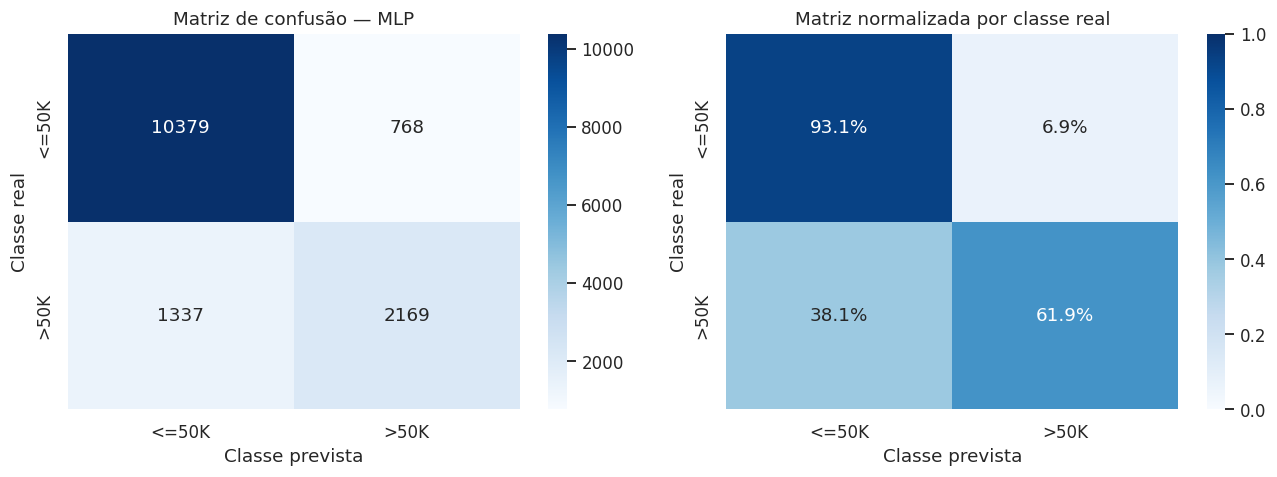

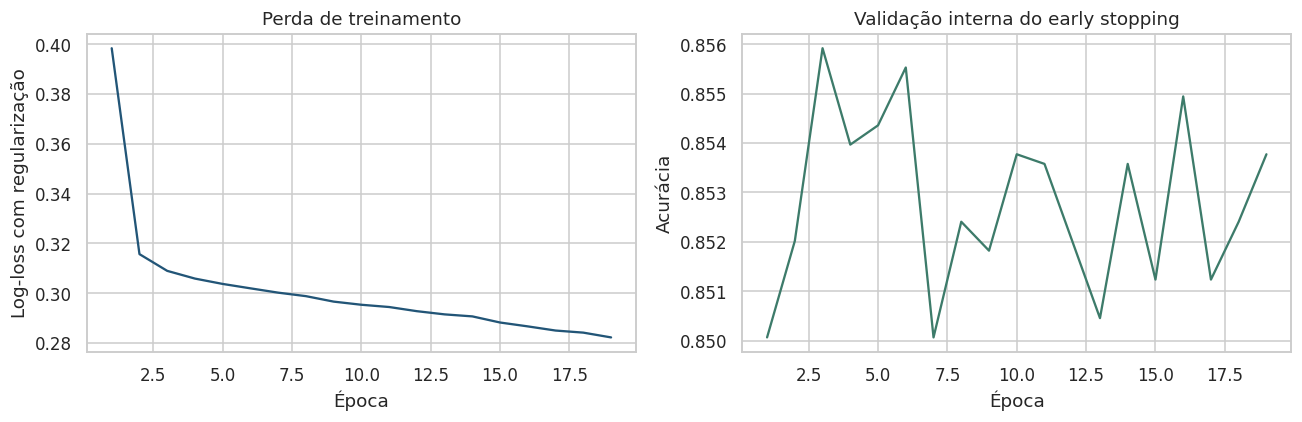

In [20]:
cm = confusion_matrix(y_test, y_pred, labels=CLASSES)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES,
            yticklabels=CLASSES, ax=axes[0])
axes[0].set(title="Matriz de confusão — MLP", xlabel="Classe prevista", ylabel="Classe real")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".1%", cmap="Blues",
            vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set(title="Matriz normalizada por classe real", xlabel="Classe prevista", ylabel="Classe real")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas = np.arange(1, len(rede.loss_curve_) + 1)
axes[0].plot(epocas, rede.loss_curve_, color="#225577")
axes[0].set(title="Perda de treinamento", xlabel="Época", ylabel="Log-loss com regularização")
axes[1].plot(epocas, rede.validation_scores_, color="#3d7b6a")
axes[1].set(title="Validação interna do early stopping", xlabel="Época", ylabel="Acurácia")
plt.tight_layout()
plt.show()

## 5. Relevância das variáveis originais

O MLP não fornece `feature_importances_`. Por isso, permutamos cada coluna original
e medimos a queda do F1 de `>50K` ao perturbar sua informação, atravessando o pipeline
completo. Assim, todas as categorias de uma variável são tratadas em conjunto.
Usamos amostra estratificada de até 2.000 registros de teste e cinco permutações por
atributo para limitar o custo.

A tabela ocupa a mesma função descritiva da tabela de importância da árvore,
mas a escala é **queda em pontos percentuais de F1**, não percentual de importância
que soma 100%. Valores negativos são mantidos; podem decorrer da amostragem ou de ruído.
Variáveis correlacionadas podem compartilhar ou mascarar sua relevância. Esta análise
é posterior à avaliação e não é usada para selecionar variáveis ou reajustar o modelo.

Variável Original,Queda média F1 (p.p.),Desvio padrão (p.p.)
marital-status,13.16,1.01
education-num,8.39,1.38
capital-gain,6.51,1.05
age,5.13,0.94
occupation,4.85,0.87
relationship,4.70,0.74
hours-per-week,3.27,0.73
workclass,1.19,0.46
capital-loss,1.14,0.47
sex,1.02,0.45


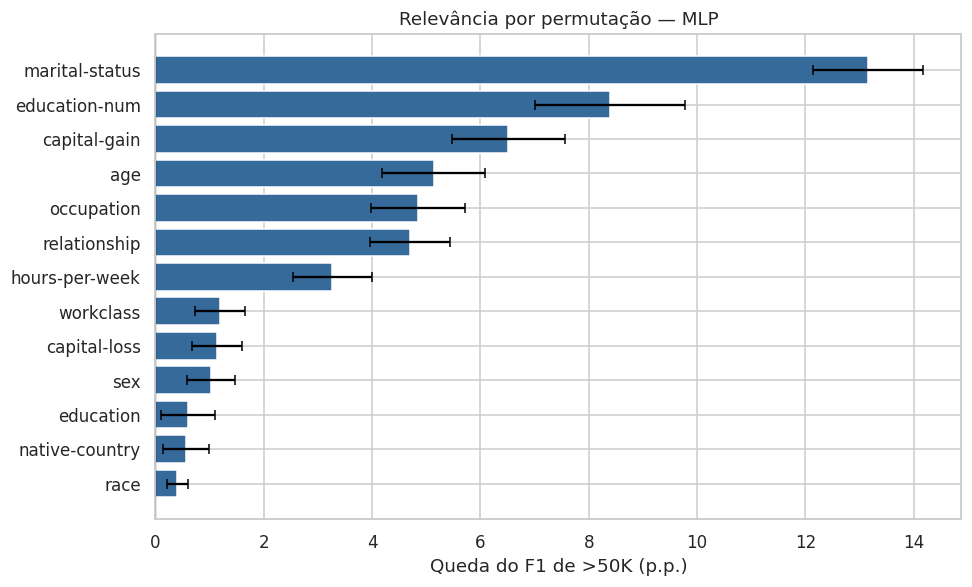

In [21]:
if len(X_test) > 2000:
    X_imp, _, y_imp, _ = train_test_split(
        X_test, y_test, train_size=2000, random_state=SEED, stratify=y_test
    )
else:
    X_imp, y_imp = X_test, y_test
scorer_f1 = make_scorer(f1_score, pos_label=1, zero_division=0)
permutacao = permutation_importance(
    model, X_imp, y_imp.map(CODIGO_CLASSES), scoring=scorer_f1,
    n_repeats=5, random_state=SEED, n_jobs=1
)
importance_grouped = pd.DataFrame({
    "Variável Original": X.columns,
    "Queda média F1 (p.p.)": permutacao.importances_mean * 100,
    "Desvio padrão (p.p.)": permutacao.importances_std * 100,
}).sort_values("Queda média F1 (p.p.)", ascending=False).reset_index(drop=True)
display(importance_grouped.style.format({
    "Queda média F1 (p.p.)": "{:.2f}", "Desvio padrão (p.p.)": "{:.2f}",
}).background_gradient(subset=["Queda média F1 (p.p.)"], cmap="Blues").hide(axis="index"))
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(importance_grouped["Variável Original"], importance_grouped["Queda média F1 (p.p.)"],
        xerr=importance_grouped["Desvio padrão (p.p.)"], color="#356a9a", capsize=3)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Relevância por permutação — MLP", xlabel="Queda do F1 de >50K (p.p.)", ylabel="")
plt.tight_layout()
plt.show()

## 6. Tabelas para a comparação posterior

A primeira tabela resume somente a rede nos três subconjuntos de validação do treino.
A segunda permite confrontar o teste da rede com os números já salvos na árvore:
0,8230 de acurácia, 0,6316 de precisão, 0,6244 de recall e 0,6279 de F1.
Os valores da árvore foram transcritos de sua saída e estão arredondados; ela não
foi treinada novamente aqui. Seu tempo não foi medido no arquivo original e permanece
ausente. Hardware e versões daquele treinamento não foram registrados.

Essa referência é **descritiva**: os algoritmos têm pré-processamentos diferentes
(a rede acrescenta escala) e falta executar todos no mesmo ambiente com o mesmo
protocolo de validação e temporização. Não se deve escolher o vencedor global do
trabalho com essa tabela parcial. Ao integrar os resultados, separe teste fixo de
validação cruzada e rotule a variação de pré-processamento utilizada.

,Algoritmo,Protocolo,Acurácia,Precisão (>50K),Recall (>50K),F1 (>50K),Tempo treino total (s)
0,Rede neural MLP,CV 3 partes nos 70% de treino,0.8544 ± 0.0010,0.7313 ± 0.0128,0.6196 ± 0.0176,0.6706 ± 0.0053,14.8042 ± 6.5348


Algoritmo,Acurácia,Precisão (>50K),Recall (>50K),F1 (>50K),Tempo treino total (s),Pré-processamento
Árvore (saída salva),0.8230,0.6316,0.6244,0.6279,Não medido,Imputação + one-hot
Rede neural MLP (esta execução),0.8563,0.7385,0.6187,0.6733,8.0623,Imputação + one-hot + StandardScaler


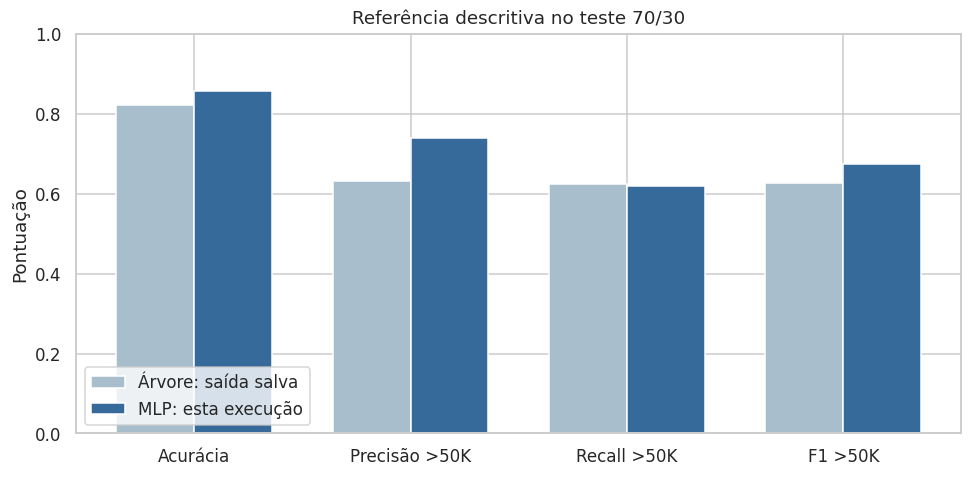

In [22]:
colunas_comparacao = ["Acurácia", "Precisão (>50K)", "Recall (>50K)", "F1 (>50K)", "Tempo treino total (s)"]
tabela_media = pd.DataFrame([{
    "Algoritmo": "Rede neural MLP", "Protocolo": "CV 3 partes nos 70% de treino",
    **{c: f"{resumo_cv.loc[c, 'Média']:.4f} ± {resumo_cv.loc[c, 'Desvio padrão']:.4f}"
       for c in colunas_comparacao},
}])
display(tabela_media)

comparacao_referencia = pd.DataFrame([
    {"Algoritmo": "Árvore (saída salva)", "Acurácia": 0.8230,
     "Precisão (>50K)": 0.6316, "Recall (>50K)": 0.6244, "F1 (>50K)": 0.6279,
     "Tempo treino total (s)": np.nan, "Pré-processamento": "Imputação + one-hot"},
    {"Algoritmo": "Rede neural MLP (esta execução)",
     **{c: metricas_teste[c] for c in colunas_comparacao[:-1]},
     "Tempo treino total (s)": tempo_total,
     "Pré-processamento": "Imputação + one-hot + StandardScaler"},
])
display(comparacao_referencia.style.format(
    {c: "{:.4f}" for c in colunas_comparacao}, na_rep="Não medido"
).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 4.5))
posicoes = np.arange(4)
ax.bar(posicoes - 0.18, comparacao_referencia.loc[0, colunas_comparacao[:-1]].astype(float),
       width=0.36, label="Árvore: saída salva", color="#a9becd")
ax.bar(posicoes + 0.18, comparacao_referencia.loc[1, colunas_comparacao[:-1]].astype(float),
       width=0.36, label="MLP: esta execução", color="#356a9a")
ax.set_xticks(posicoes, ["Acurácia", "Precisão >50K", "Recall >50K", "F1 >50K"])
ax.set(ylim=(0, 1), ylabel="Pontuação", title="Referência descritiva no teste 70/30")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 7. Interpretação dos resultados

A interpretação abaixo é gerada com os resultados desta execução. Melhor e pior
classe são definidos pelo F1, que combina precisão e recall; diferenças em outros
critérios podem levar a outra ordenação.

In [23]:
por_classe = relatorio_classes.loc[CLASSES]
melhor_classe = por_classe["f1-score"].idxmax()
pior_classe = por_classe["f1-score"].idxmin()
classe_majoritaria = y_train.value_counts().idxmax()
acuracia_majoritaria = accuracy_score(y_test, np.repeat(classe_majoritaria, len(y_test)))
tn, fp, fn, tp = cm.ravel()
delta_arvore = (accuracy - 0.8230) * 100
display(Markdown(f"""
No teste com **{len(y_test):,} exemplos**, a rede obteve **{accuracy:.2%} de acurácia**,
**{precision:.4f} de precisão**, **{recall:.4f} de recall** e **{f1:.4f} de F1** para `>50K`.
O treinamento completo levou **{tempo_total:.2f} segundos**, incluindo imputação,
codificação e escala; somente o ajuste da rede levou **{tempo_rede:.2f} segundos**.

A classe com melhor F1 foi **`{melhor_classe}`**: precisão
**{por_classe.loc[melhor_classe, 'precision']:.4f}**, recall
**{por_classe.loc[melhor_classe, 'recall']:.4f}** e F1
**{por_classe.loc[melhor_classe, 'f1-score']:.4f}**. A classe de menor F1 foi
**`{pior_classe}`**: precisão **{por_classe.loc[pior_classe, 'precision']:.4f}**,
recall **{por_classe.loc[pior_classe, 'recall']:.4f}** e F1
**{por_classe.loc[pior_classe, 'f1-score']:.4f}**.

Para a classe `>50K`, houve **{tp:,} verdadeiros positivos**, **{fn:,} falsos negativos**
e **{fp:,} falsos positivos**. Prever sempre a classe majoritária do treino
(`{classe_majoritaria}`) alcançaria **{acuracia_majoritaria:.2%} de acurácia**, mostrando
por que acurácia isolada é insuficiente nesse dataset desbalanceado.

Na validação cruzada do treino, a acurácia média foi
**{resumo_cv.loc['Acurácia', 'Média']:.4f} ± {resumo_cv.loc['Acurácia', 'Desvio padrão']:.4f}**,
e o F1 de `>50K` foi **{resumo_cv.loc['F1 (>50K)', 'Média']:.4f} ±
{resumo_cv.loc['F1 (>50K)', 'Desvio padrão']:.4f}**. A diferença descritiva de acurácia
em relação à saída salva da árvore foi **{delta_arvore:+.2f} pontos percentuais**.
Essa diferença não é um teste de significância nem estabelece o melhor dos três
algoritmos exigidos, pois a avaliação conjunta ainda precisa ser feita.
"""))


No teste com **14,653 exemplos**, a rede obteve **85.63% de acurácia**,
**0.7385 de precisão**, **0.6187 de recall** e **0.6733 de F1** para `>50K`.
O treinamento completo levou **8.06 segundos**, incluindo imputação,
codificação e escala; somente o ajuste da rede levou **7.93 segundos**.

A classe com melhor F1 foi **`<=50K`**: precisão
**0.8859**, recall
**0.9311** e F1
**0.9079**. A classe de menor F1 foi
**`>50K`**: precisão **0.7385**,
recall **0.6187** e F1
**0.6733**.

Para a classe `>50K`, houve **2,169 verdadeiros positivos**, **1,337 falsos negativos**
e **768 falsos positivos**. Prever sempre a classe majoritária do treino
(`<=50K`) alcançaria **76.07% de acurácia**, mostrando
por que acurácia isolada é insuficiente nesse dataset desbalanceado.

Na validação cruzada do treino, a acurácia média foi
**0.8544 ± 0.0010**,
e o F1 de `>50K` foi **0.6706 ±
0.0053**. A diferença descritiva de acurácia
em relação à saída salva da árvore foi **+3.33 pontos percentuais**.
Essa diferença não é um teste de significância nem estabelece o melhor dos três
algoritmos exigidos, pois a avaliação conjunta ainda precisa ser feita.


### Limitações para o relatório

O Adult reflete um contexto histórico específico, e seu limiar de renda é nominal
daquela época. `race` e `sex` foram mantidos porque o notebook de referência os usa;
bons resultados agregados não demonstram equidade entre grupos nem autorizam uso
em decisões individuais. Não há inferência causal sobre os efeitos dos atributos.

Repetições exatas de registros e a redundância de escolaridade podem afetar
interpretação e avaliação. Não houve balanceamento artificial, exclusão de atributos,
busca de arquitetura ou ajuste de limiar. Esses seriam novos experimentos e exigiriam
uma avaliação separada para todos os algoritmos, sem reutilizar este teste para seleção.
A dupla ainda deve comparar os três modelos, descrever melhor e pior algoritmo sob
um critério declarado e redigir o relatório final.

## 9. Exportação local opcional

Esta célula vem desativada. Ao definir `EXPORTAR = True`, escolha uma pasta **fora
de qualquer repositório**. Ela grava dados originais e limpos, matrizes transformadas,
pipeline treinado, índices da divisão, previsões, tabelas, metadados e logs locais.
O notebook em si já contém o código e os gráficos. Nenhum comando Git é executado.
Os tempos apresentados nas tabelas não incluem exportação, download ou gráficos.

In [25]:
EXPORTAR = False
PASTA_EXPORTACAO = Path("/content/Adult_MLP_resultados")
if EXPORTAR:
    import joblib
    from scipy import sparse
    PASTA_EXPORTACAO.mkdir(parents=True, exist_ok=True)
    dataset_original.to_csv(PASTA_EXPORTACAO / "adult_original_ucimlrepo.csv", index=False)
    dataset.to_csv(PASTA_EXPORTACAO / "adult_limpo_com_fnlwgt.csv", index=False)
    pd.concat([X, y], axis=1).to_csv(PASTA_EXPORTACAO / "adult_entrada_modelo.csv", index=False)
    for nome, entradas, alvo in [("treino", X_train, y_train), ("teste", X_test, y_test)]:
        matriz = model.named_steps["preprocessor"].transform(entradas)
        sparse.save_npz(PASTA_EXPORTACAO / f"X_{nome}_transformado.npz", sparse.csr_matrix(matriz))
        alvo.to_csv(PASTA_EXPORTACAO / f"y_{nome}_com_indices.csv", index=True)
    pd.Series(model.named_steps["preprocessor"].get_feature_names_out(), name="Entrada").to_csv(
        PASTA_EXPORTACAO / "nomes_entradas_transformadas.csv", index=False)
    for nome, tabela in {
        "caracterizacao": caracterizacao, "desbalanceamento": desbalanceamento,
        "validacao_cruzada": resultados_cv, "resumo_cv": resumo_cv,
        "metricas_teste": pd.DataFrame([metricas_teste]), "classes": relatorio_classes,
        "relevancia": importance_grouped, "comparacao_referencia": comparacao_referencia,
        "previsoes_teste": resultados.assign(indice_original=X_test.index),
        "curva_treino": pd.DataFrame({"Perda": rede.loss_curve_, "Acurácia validação": rede.validation_scores_}),
        "matriz_confusao": pd.DataFrame(cm, index=CLASSES, columns=CLASSES),
    }.items():
        tabela.to_csv(PASTA_EXPORTACAO / f"{nome}.csv", index=True)
    joblib.dump(model, PASTA_EXPORTACAO / "pipeline_mlp.joblib")
    metadados = {
        "fonte": "https://archive.ics.uci.edu/dataset/2/adult", "hash_csv_fonte": hash_fonte,
        "hash_indices_teste": hash_indices_teste, "seed": SEED,
        "sistema": platform.platform(), "processador": platform.processor(),
        "threads": threadpool_info(), "data_utc": datetime.now(timezone.utc).isoformat(),
        "parametros_mlp": clf.get_params(), "codigo_classes": CODIGO_CLASSES, "tempo_pre_s": tempo_pre,
        "tempo_rede_s": tempo_rede, "tempo_total_s": tempo_total,
        "tempo_predicao_s": tempo_predicao, "avisos_treino": avisos_treino,
    }
    (PASTA_EXPORTACAO / "execucao.json").write_text(
        json.dumps(metadados, ensure_ascii=False, indent=2), encoding="utf-8")
    print("Exportação concluída em:", PASTA_EXPORTACAO.resolve())
else:
    print("Exportação desativada. Nenhum arquivo de resultados foi gravado pelas células.")

Exportação concluída em: /root/Downloads/Adult_MLP_resultados


In [26]:
import shutil
from google.colab import files

arquivo_zip = shutil.make_archive(
    "/content/Adult_MLP_resultados",
    "zip",
    root_dir=str(PASTA_EXPORTACAO),
)

files.download(arquivo_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>